In [36]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn .decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [37]:
wl = np.load('free_chem_data/wl_binned.npy')
print("Wavelength loaded sucessfully")
data = np.load('free_chem_data/clean_final_spec.npy')
print("Spectra loaded sucessfully")


Wavelength loaded sucessfully
Spectra loaded sucessfully


In [38]:
# basic structure
print(f"Wavelength grid shape : {wl.shape}")
print(f"Wavelength range      : {wl.min():.3f} to {wl.max():.3f} μm")
print(f"Full data shape       : {data.shape}")
print(f"Number of planets     : {data.shape[0]}")
print(f"Total features        : {data.shape[1]}")
print(f"NaN values            : {np.isnan(data).sum()}")
print(f"Inf values            : {np.isinf(data).sum()}")

Wavelength grid shape : (52,)
Wavelength range      : 0.550 to 7.276 μm
Full data shape       : (98495, 62)
Number of planets     : 98495
Total features        : 62
NaN values            : 0
Inf values            : 0


In [39]:
n_wl = 52
spectra = data[:, :52]
params  = data[:, 52:]

print("Data shape:", data.shape)
print("Spectra shape:", spectra.shape)
print("Params shape:", params.shape)
print("wl_binned length:", len(wl))
print("First wl:", wl[0])
print("Last wl:", wl[-1])

# Then all your EDA plots from before using the corrected spectra and params

Data shape: (98495, 62)
Spectra shape: (98495, 52)
Params shape: (98495, 10)
wl_binned length: 52
First wl: 0.55
Last wl: 7.2755592


In [40]:
param_names = ['Rstar_Rs', 'Rp_Rj', 'Mp_Mj', 'T','log_H2O', 'log_CH4', 'log_CO','log_CO2', 'log_NH3', 'na_param']
print(f"\nSpectrum bins : {spectra.shape[1]}")
print(f"Parameters    : {params.shape[1]}")



Spectrum bins : 52
Parameters    : 10


In [41]:
print("\n==Parameter Ranges==")
for i,name in enumerate(param_names):
    if i<params.shape[1]:
        print(f"{name}: {params[:,i].min():.3f} to {params[:,i].max():.3f}")



==Parameter Ranges==
Rstar_Rs: 0.500 to 2.000
Rp_Rj: 0.100 to 2.000
Mp_Mj: 0.011 to 5.000
T: 300.006 to 2999.985
log_H2O: -9.000 to -3.000
log_CH4: -9.000 to -3.000
log_CO: -9.000 to -3.000
log_CO2: -9.000 to -3.000
log_NH3: -9.000 to -3.000
na_param: 1.000 to 1.000


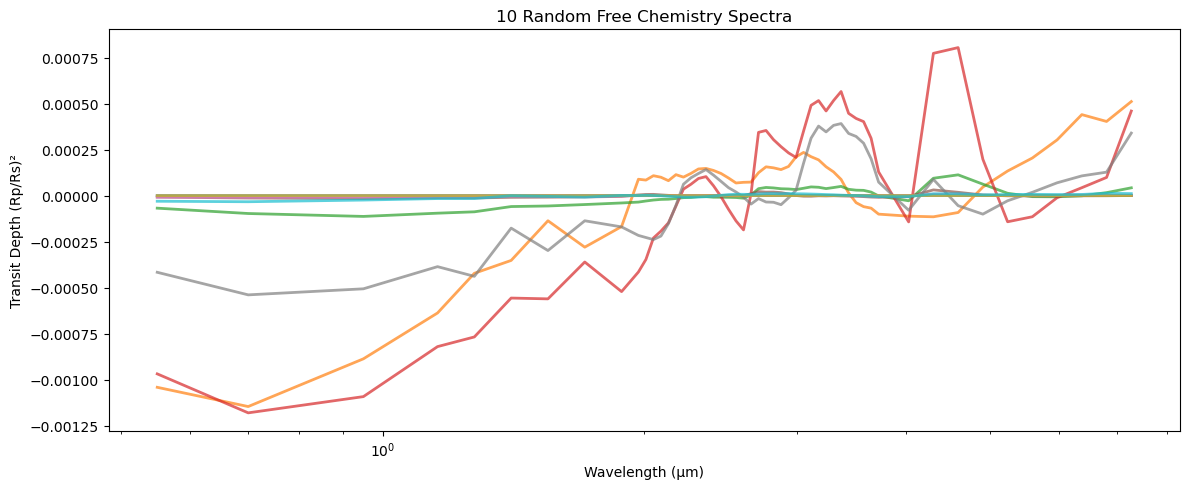

Plot 1 done


In [42]:
# plotting 10 spectras
fig,ax = plt.subplots(figsize=(12,5))
idx = np.random.choice(len(spectra),10,replace=False)
for i in idx:
    #ax.plot(wl,spectra[i],alpha=0.6,linewidth=2)
    spec_normalised = spectra[i] - spectra[i].mean()
    ax.plot(wl, spec_normalised, alpha=0.7, linewidth=2)
ax.set_xlabel('Wavelength (μm)')
ax.set_ylabel('Transit Depth (Rp/Rs)²')
ax.set_title('10 Random Free Chemistry Spectra')
ax.set_xscale('log')
plt.tight_layout()
plt.savefig('plot1_sample_spectra.png', dpi=150)
plt.show()
print("Plot 1 done")

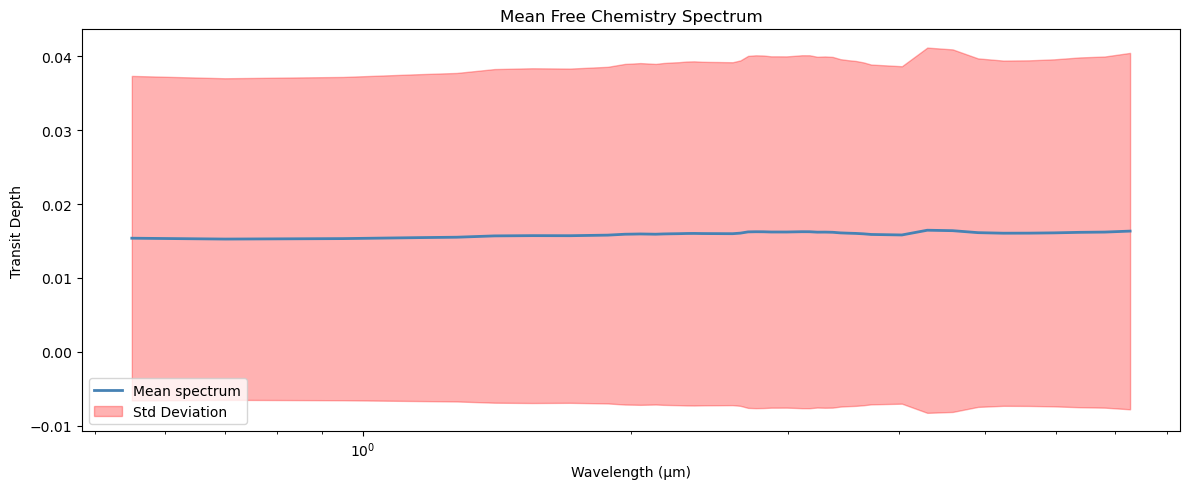

Plot 2 done

Highest variance at wavelength: 4.305 μm
Lowest variance at wavelength : 0.700 μm


In [43]:
# mean spectrum with std

mean_spec = spectra.mean(axis=0)
std_spec = spectra.std(axis=0)
fig,ax = plt.subplots(figsize=(12,5))
ax.plot(wl,mean_spec,color='steelblue',linewidth=2,label='Mean spectrum')
ax.fill_between(wl, mean_spec - std_spec, mean_spec + std_spec,alpha = 0.3, color = 'red', label="Std Deviation")
ax.set_xlabel('Wavelength (μm)')
ax.set_ylabel('Transit Depth')
ax.set_title('Mean Free Chemistry Spectrum')
ax.set_xscale('log')
ax.legend()
plt.tight_layout()
plt.savefig('plot2_mean_spectrum.png', dpi=150)
plt.show()
print("Plot 2 done")
print(f"\nHighest variance at wavelength: {wl[std_spec.argmax()]:.3f} μm")
print(f"Lowest variance at wavelength : {wl[std_spec.argmin()]:.3f} μm")

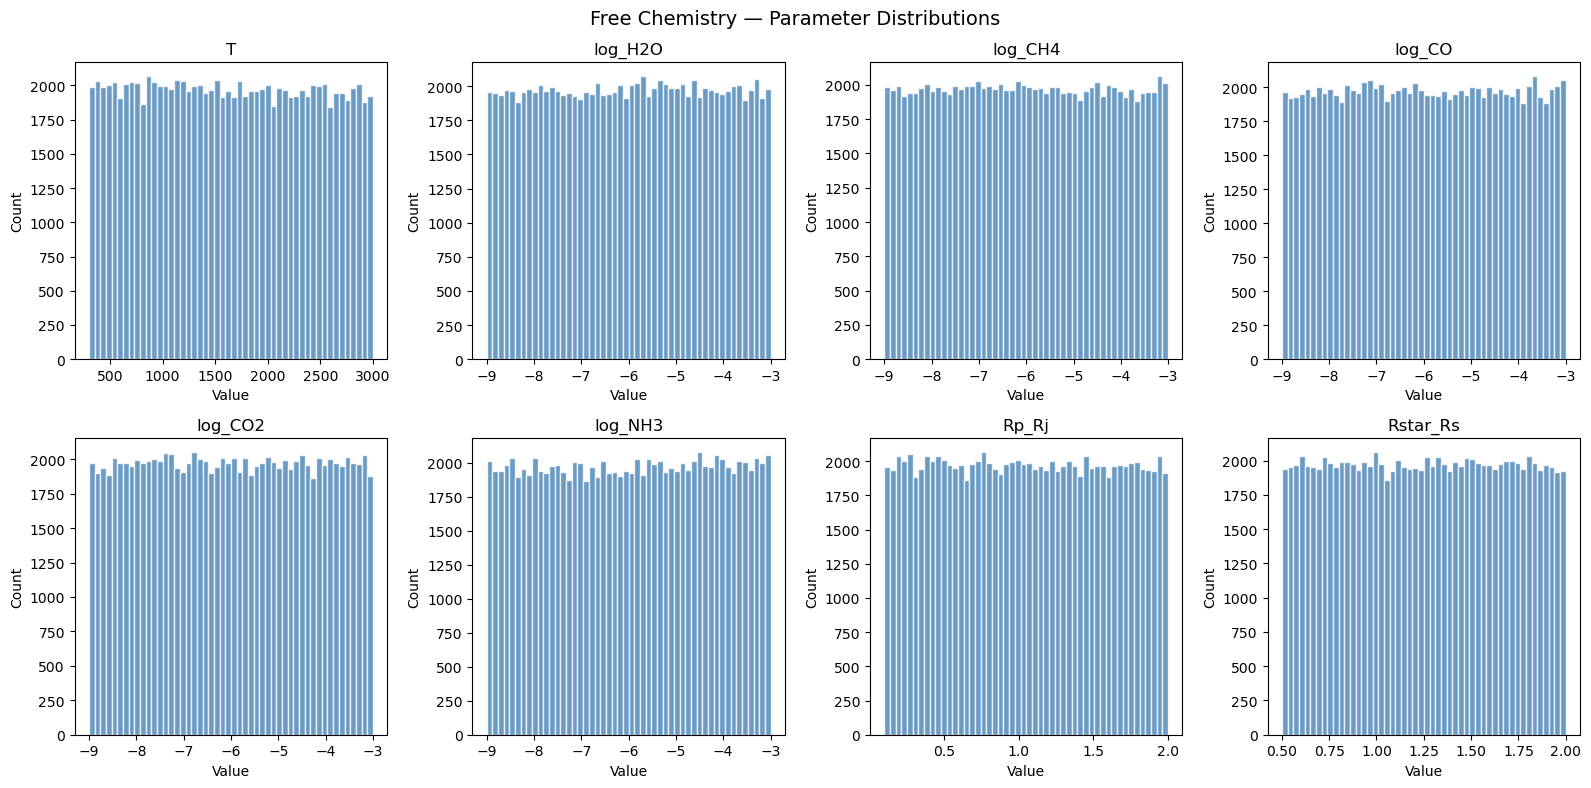

Plot 3 done


In [44]:
# parameter distribution
plot_params = ['T', 'log_H2O', 'log_CH4','log_CO', 'log_CO2', 'log_NH3','Rp_Rj', 'Rstar_Rs']
plot_idx    = [3, 4, 5, 6, 7, 8, 1, 0]

fig,axes = plt.subplots(2,4,figsize=(16,8))
axes = axes.flatten()

for i,(name,pidx) in enumerate(zip(plot_params,plot_idx)):
    if pidx<params.shape[1]:
        axes[i].hist(params[:,pidx],bins=50,color='steelblue',edgecolor='white',alpha=0.8)
        axes[i].set_title(name)
        axes[i].set_xlabel('Value')
        axes[i].set_ylabel('Count')
plt.suptitle('Free Chemistry — Parameter Distributions',fontsize=14)
plt.tight_layout()
plt.savefig('plot3_param_distributions.png', dpi=150)
plt.show()
print("Plot 3 done")

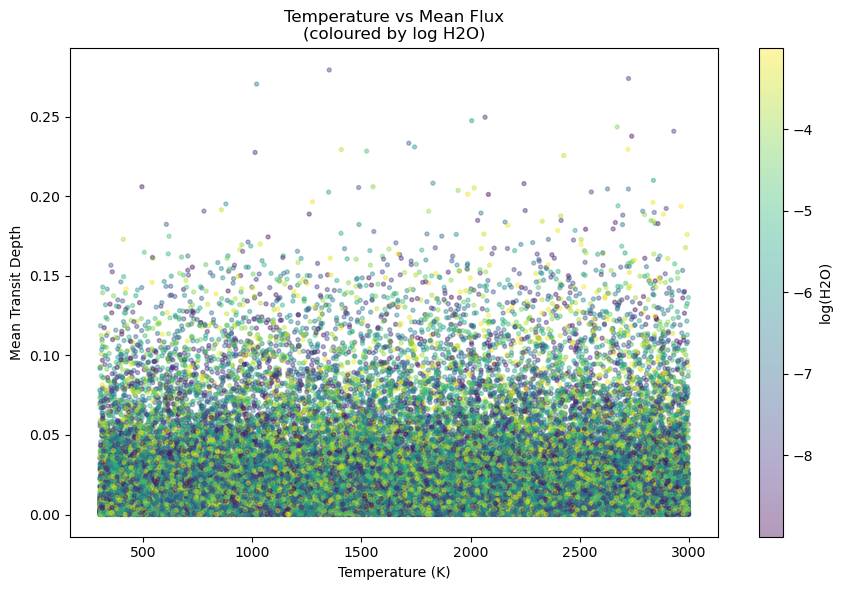

Plot 4 done


In [45]:
# temp vs flux
T_vals    = params[:, 3]
mean_flux = spectra.mean(axis=1)
logH2O    = params[:, 4]

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(T_vals, mean_flux,c=logH2O, cmap='viridis',alpha=0.4, s=8)
plt.colorbar(sc, label='log(H2O)')
ax.set_xlabel('Temperature (K)')
ax.set_ylabel('Mean Transit Depth')
ax.set_title('Temperature vs Mean Flux\n(coloured by log H2O)')
plt.tight_layout()
plt.savefig('plot4_T_vs_flux.png', dpi=150)
plt.show()
print("Plot 4 done")

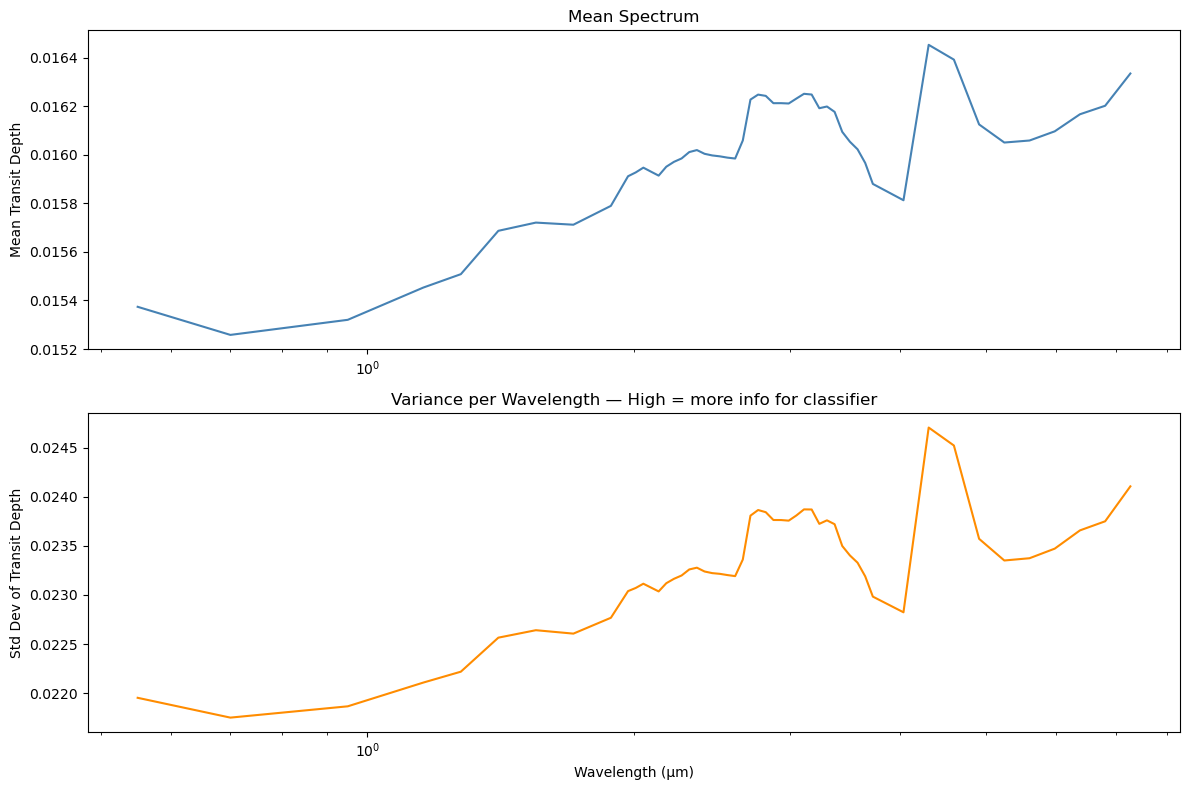

Plot 5 done

Top 5 most variable wavelength bins:
  4.305 μm  —  std = 0.024703
  4.597 μm  —  std = 0.024520
  7.276 μm  —  std = 0.024105
  3.113 μm  —  std = 0.023870
  3.175 μm  —  std = 0.023869


In [46]:
# variance per wavelength bin
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(wl, mean_spec, color='steelblue', linewidth=1.5)
axes[0].set_ylabel('Mean Transit Depth')
axes[0].set_title('Mean Spectrum')
axes[0].set_xscale('log')

axes[1].plot(wl, std_spec, color='darkorange', linewidth=1.5)
axes[1].set_ylabel('Std Dev of Transit Depth')
axes[1].set_title('Variance per Wavelength — High = more info for classifier')
axes[1].set_xlabel('Wavelength (μm)')
axes[1].set_xscale('log')

plt.tight_layout()
plt.savefig('plot5_variance_per_wavelength.png', dpi=150)
plt.show()
print("Plot 5 done")

# Top 5 most informative wavelength bins
top5_idx = std_spec.argsort()[-5:][::-1]
print("\nTop 5 most variable wavelength bins:")
for idx in top5_idx:
    print(f"  {wl[idx]:.3f} μm  —  std = {std_spec[idx]:.6f}")

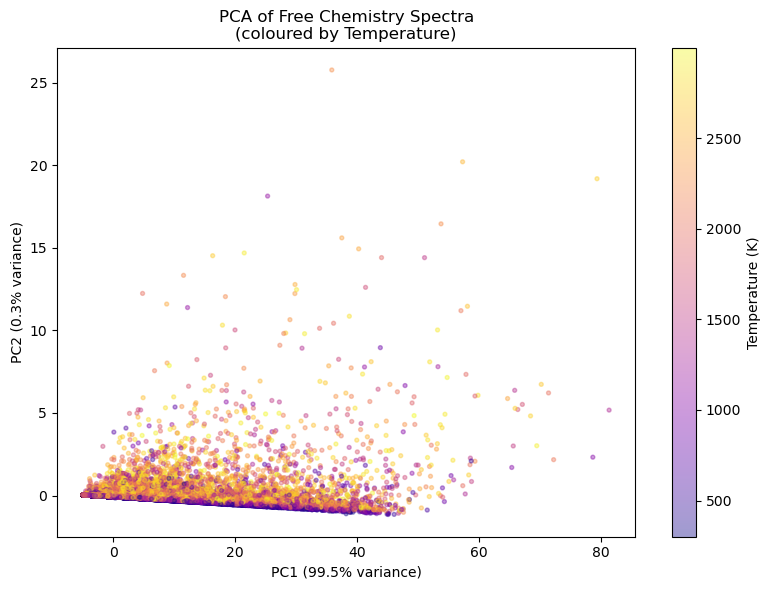

Plot 6 done

PC1 explains: 99.5% of variance
PC2 explains: 0.3% of variance
Total explained: 99.8%


In [47]:
# pca
scaler  = StandardScaler()
X_scaled = scaler.fit_transform(spectra)

pca    = PCA(n_components=2)
X_pca  = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                c=params[:, 3],   # colour by temperature
                cmap='plasma',
                alpha=0.4, s=8)
plt.colorbar(sc, label='Temperature (K)')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('PCA of Free Chemistry Spectra\n(coloured by Temperature)')
plt.tight_layout()
plt.savefig('plot6_pca_free_chemistry.png', dpi=150)
plt.show()

print("Plot 6 done")
print(f"\nPC1 explains: {pca.explained_variance_ratio_[0]*100:.1f}% of variance")
print(f"PC2 explains: {pca.explained_variance_ratio_[1]*100:.1f}% of variance")
print(f"Total explained: {pca.explained_variance_ratio_[:2].sum()*100:.1f}%")

In [48]:
Rp = params[:, 1]     # Rp in Jupiter radii
Rs = params[:, 0]     # Rstar in solar radii
# Convert to same units — 1 Jupiter radius = 0.10045 solar radii
Rp_Rs = (Rp * 0.10045) / Rs
geometric_depth = Rp_Rs**2
spectra_normalised = spectra / geometric_depth[:, np.newaxis]

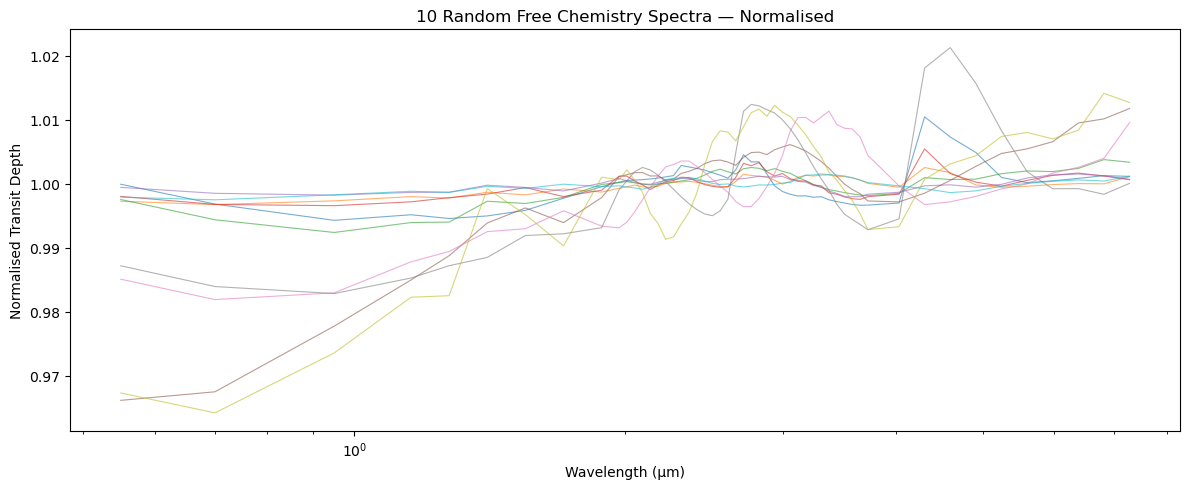

PC1 after normalisation: 41.3%
PC2 after normalisation: 30.7%


In [49]:
# Normalise by mean
spectra_norm = spectra / spectra.mean(axis=1, keepdims=True)

# Plot 10 random normalised spectra
fig, ax = plt.subplots(figsize=(12, 5))
idx = np.random.choice(len(spectra_norm), 10, replace=False)
for i in idx:
    ax.plot(wl, spectra_norm[i], alpha=0.6, linewidth=0.8)
ax.set_xlabel('Wavelength (μm)')
ax.set_ylabel('Normalised Transit Depth')
ax.set_title('10 Random Free Chemistry Spectra — Normalised')
ax.set_xscale('log')
plt.tight_layout()
plt.show()

# PCA on normalised spectra
scaler = StandardScaler()
X_scaled_norm = scaler.fit_transform(spectra_norm)
pca_norm = PCA(n_components=2)
X_pca_norm = pca_norm.fit_transform(X_scaled_norm)

print(f"PC1 after normalisation: {pca_norm.explained_variance_ratio_[0]*100:.1f}%")
print(f"PC2 after normalisation: {pca_norm.explained_variance_ratio_[1]*100:.1f}%")